Processing scale factor: 1.0
Processing scale factor: 0.75
Processing scale factor: 0.6
Processing scale factor: 0.5
Processing scale factor: 0.4
Processing scale factor: 0.3
Processing scale factor: 0.2

=== Binary Metrics (Class 1 vs Others) ===
   scale_factor  resolution_m_per_px  precision    recall        f1
0          1.00             0.050000   0.021761  0.236397  0.039853
1          0.75             0.066667   0.023015  0.265124  0.042354
2          0.60             0.083333   0.023849  0.281500  0.043973
3          0.50             0.100000   0.025741  0.337114  0.047830
4          0.40             0.125000   0.026303  0.345391  0.048884
5          0.30             0.166667   0.027407  0.411036  0.051387
6          0.20             0.250000   0.027819  0.482301  0.052603


In [ ]:
import re
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from sklearn.metrics import precision_score, recall_score, f1_score
from pathlib import Path
import tifffile as tiff
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------
# Configuration
BASE_RES_M = 0.05
IMG_DIR  = Path("../../data/tiled_data/images")
MASK_DIR = Path("../../data/tiled_data/masks")
MODEL    = load_model("models_multiclass/best_unet_model.keras", compile=False)

# TARGET_CLASS defines which class we are treating as "Positive"
TARGET_CLASS = 1 

def extract_number(fname):
    m = re.search(r"\d+", fname)
    return int(m.group()) if m else None

def load_mask(path, target_size=(256, 256)):
    m = tiff.imread(path).astype(np.uint8)
    if m.ndim == 3:
        m = m[..., 0]
    m = tf.image.resize(m[..., None], target_size, method="nearest")
    return np.squeeze(m).astype(np.uint8)

# Match images and masks
images = sorted(IMG_DIR.glob("*.tif"))
masks  = {extract_number(m.name): m for m in sorted(MASK_DIR.glob("*.tif"))}
pairs  = [(img, masks[extract_number(img.name)])
          for img in images if extract_number(img.name) in masks]

if not pairs:
    raise RuntimeError("No matched image–mask pairs.")

# -------------------------------------------------
res_factors = [1.0, 0.75, 0.6, 0.5, 0.4, 0.3, 0.2] # Shortened for example
results = []

for f in res_factors:
    print(f"Processing scale factor: {f}")
    y_true_all, y_pred_all = [], []

    for img_p, mask_p in pairs:
        img = tiff.imread(str(img_p)).astype(np.float32)
        if img.ndim == 2: img = np.stack([img]*3, -1)
        elif img.shape[-1] == 4: img = img[..., :3]

        # 1. Load Ground Truth and force it to be binary (Target vs Rest)
        mask = load_mask(mask_p)
        binary_mask = (mask == TARGET_CLASS).astype(np.uint8)

        # Preprocess Image
        h, w = int(img.shape[0]*f), int(img.shape[1]*f)
        img_res = tf.image.resize(img, (max(1,h), max(1,w)), method="bilinear")
        x = tf.image.resize(img_res, (256, 256), method="bilinear") / 255.0
        x = np.expand_dims(x, 0)

        # 2. Get Model Prediction
        pred = MODEL.predict(x, verbose=0)[0]
        
        # Determine prediction based on model output shape
        if pred.shape[-1] > 1:
            # Multiclass case: take the highest probability channel
            pred_class = np.argmax(pred, axis=-1)
            pred_binary = (pred_class == TARGET_CLASS).astype(np.uint8)
        else:
            # Single channel sigmoid case
            pred_binary = (pred > 0.5).astype(np.uint8)

        y_true_all.append(binary_mask.ravel())
        y_pred_all.append(pred_binary.ravel())

    # Flatten the lists into single numpy arrays for scoring
    y_true_flat = np.concatenate(y_true_all)
    y_pred_flat = np.concatenate(y_pred_all)

    results.append({
        "scale_factor": f,
        "resolution_m_per_px": BASE_RES_M / f,
        "precision": precision_score(y_true_flat, y_pred_flat, zero_division=0),
        "recall":    recall_score(y_true_flat, y_pred_flat, zero_division=0),
        "f1":        f1_score(y_true_flat, y_pred_flat, zero_division=0),
    })

df = pd.DataFrame(results).sort_values("resolution_m_per_px")
print("\n=== Binary Metrics (Class 1 vs Others) ===")
print(df)

# Plotting code remains the same...

In [13]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

# 1. Re-establish the mapping from your training logs
LABEL_LIST = [1, 2, 3, 4, 5, 7, 8, 9, 99]
LABEL_MAP = {val: i for i, val in enumerate(LABEL_LIST)}

# Set your target
TARGET_LABEL = 1
INTERNAL_IDX = LABEL_MAP[TARGET_LABEL] 

results = []

print(f"Evaluating Performance for Original Label {TARGET_LABEL} (Internal Index {INTERNAL_IDX})")

for f in res_factors:
    y_true_all, y_pred_all = [], []

    for img_p, mask_p in pairs:
        # Load and preprocess (consistent with your training generator)
        img = tiff.imread(str(img_p)).astype(np.float32)
        if img.ndim == 2: img = np.stack([img]*3, -1)
        elif img.shape[-1] == 4: img = img[..., :3]

        # Load Ground Truth and isolate the TARGET_LABEL
        mask = load_mask(mask_p)
        binary_mask_gt = (mask == TARGET_LABEL).astype(np.uint8)

        # Resizing logic (matches your resolution study)
        h, w = int(img.shape[0]*f), int(img.shape[1]*f)
        img_res = tf.image.resize(img, (max(1,h), max(1,w)), method="bilinear")
        x = tf.image.resize(img_res, (256, 256), method="bilinear") / 255.0
        x = np.expand_dims(x, 0)

        # 2. Prediction Logic: Multiclass to Binary
        pred_probs = MODEL.predict(x, verbose=0)[0] 
        pred_classes = np.argmax(pred_probs, axis=-1)
        
        # Binary result: Is the winner our class?
        binary_pred = (pred_classes == INTERNAL_IDX).astype(np.uint8)

        y_true_all.append(binary_mask_gt.ravel())
        y_pred_all.append(binary_pred.ravel())

    # Flatten for metrics
    y_true_flat = np.concatenate(y_true_all)
    y_pred_flat = np.concatenate(y_pred_all)

    # 3. Calculate Binary Metrics
    results.append({
        "scale_factor": f,
        "resolution_m_per_px": BASE_RES_M / f,
        "precision": precision_score(y_true_flat, y_pred_flat, zero_division=0),
        "recall":    recall_score(y_true_flat, y_pred_flat, zero_division=0),
        "f1":        f1_score(y_true_flat, y_pred_flat, zero_division=0),
    })

df_results = pd.DataFrame(results).sort_values("resolution_m_per_px")
print(df_results)

Evaluating Performance for Original Label 1 (Internal Index 0)
   scale_factor  resolution_m_per_px  precision    recall        f1
0          1.00             0.050000   0.058931  0.153170  0.085115
1          0.75             0.066667   0.056884  0.138386  0.080626
2          0.60             0.083333   0.055680  0.127879  0.077581
3          0.50             0.100000   0.050969  0.096410  0.066684
4          0.40             0.125000   0.048810  0.085429  0.062125
5          0.30             0.166667   0.043606  0.049399  0.046322
6          0.20             0.250000   0.035271  0.018341  0.024133


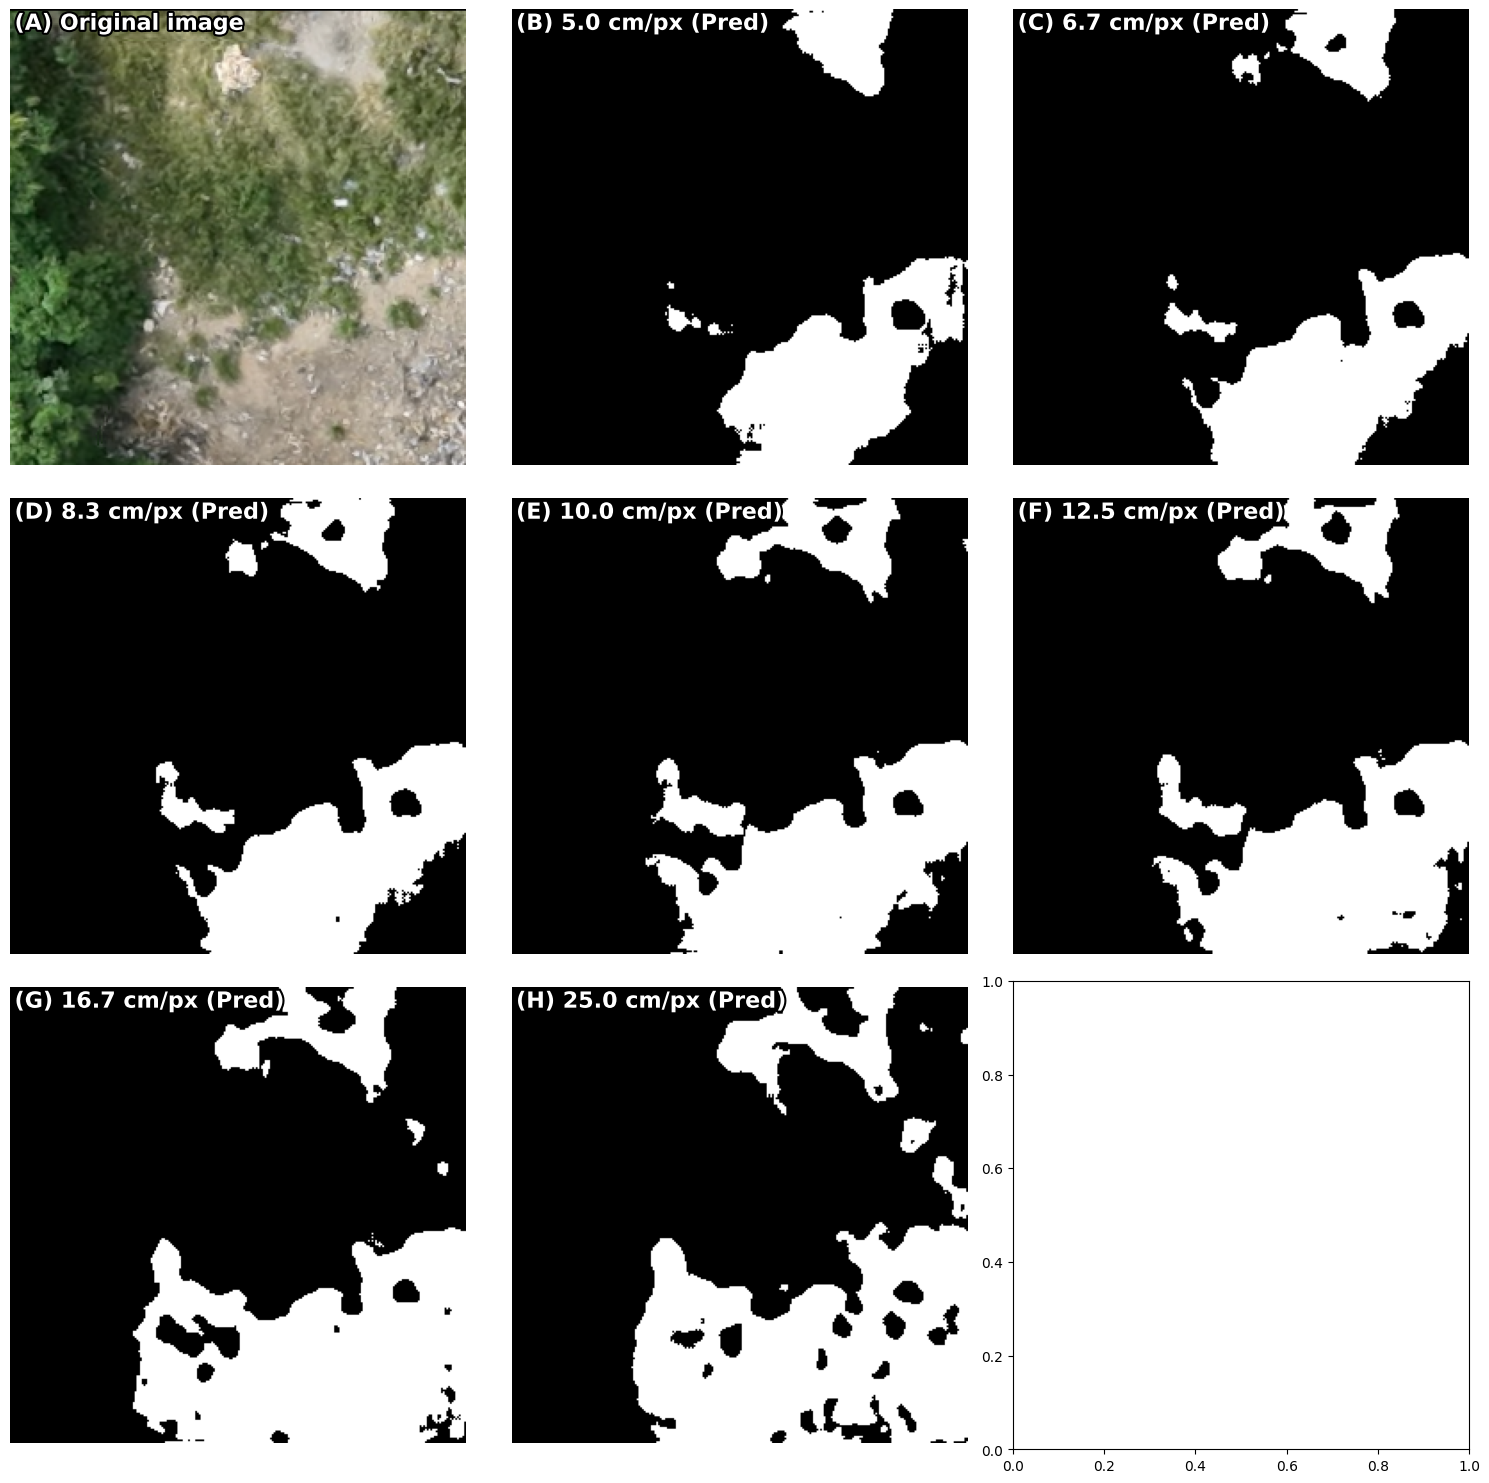

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects

# Select image 45
img_num = 256
pair_45 = [p for p in pairs if extract_number(p[0].name) == img_num]
if not pair_45:
    raise RuntimeError(f"Image {img_num} not found in matched pairs.")
img_path, mask_path = pair_45[0]

# Load original image
img_orig = tiff.imread(str(img_path)).astype(np.float32)
if img_orig.ndim == 2:
    img_orig = np.stack([img_orig]*3, -1)
elif img_orig.shape[-1] == 4:
    img_orig = img_orig[..., :3]

# Load mask (Ground Truth)
mask_orig = load_mask(mask_path)
# Binarize Ground Truth for Class 1
mask_binary_gt = (mask_orig == 1).astype(np.uint8)

# Sort scale factors in decreasing order (fine → coarse)
sorted_factors = sorted(res_factors, reverse=True)

# Letters for labeling
letters = "ABCDEFGHI"

def add_halo_text(ax, text, x=0.01, y=0.99, fontsize=16):
    ax.text(
        x, y, text, fontsize=fontsize, fontweight="bold", color="white",
        va="top", ha="left", transform=ax.transAxes, zorder=2,
        path_effects=[path_effects.withStroke(linewidth=3, foreground='black')]
    )

# Initialize figure
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.flatten()

# Plot A: Original image
axes[0].imshow(tf.cast(img_orig, tf.uint8))
add_halo_text(axes[0], f"({letters[0]}) Original image")
axes[0].axis("off")

# Loop over remaining scale factors to show predictions
for i, f in enumerate(sorted_factors[:8], start=1):
    # Downsample and prepare input
    h, w = int(img_orig.shape[0]*f), int(img_orig.shape[1]*f)
    img_res = tf.image.resize(img_orig, (max(1,h), max(1,w)), method="bilinear")
    x = tf.image.resize(img_res, (256, 256), method="bilinear") / 255.0
    x = np.expand_dims(x, 0)

    # 1. Predict and isolate Class 1
    pred = MODEL.predict(x, verbose=0)[0]
    
    if pred.shape[-1] > 1:
        # Multiclass: Get argmax and check if it matches Class 1
        pred_class = np.argmax(pred, axis=-1)
        pred_bin = (pred_class == 1).astype(np.uint8)
    else:
        # Binary: Standard threshold
        pred_bin = (pred > 0.5).astype(np.uint8)

    # 2. Compute ground resolution in cm/pixel
    res_cm = (BASE_RES_M / f) * 100
    
    # 3. Display the binary prediction
    axes[i].imshow(pred_bin, cmap="gray")
    add_halo_text(axes[i], f"({letters[i]}) {res_cm:.1f} cm/px (Pred)")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

TypeError: Invalid shape (256, 256, 9) for image data

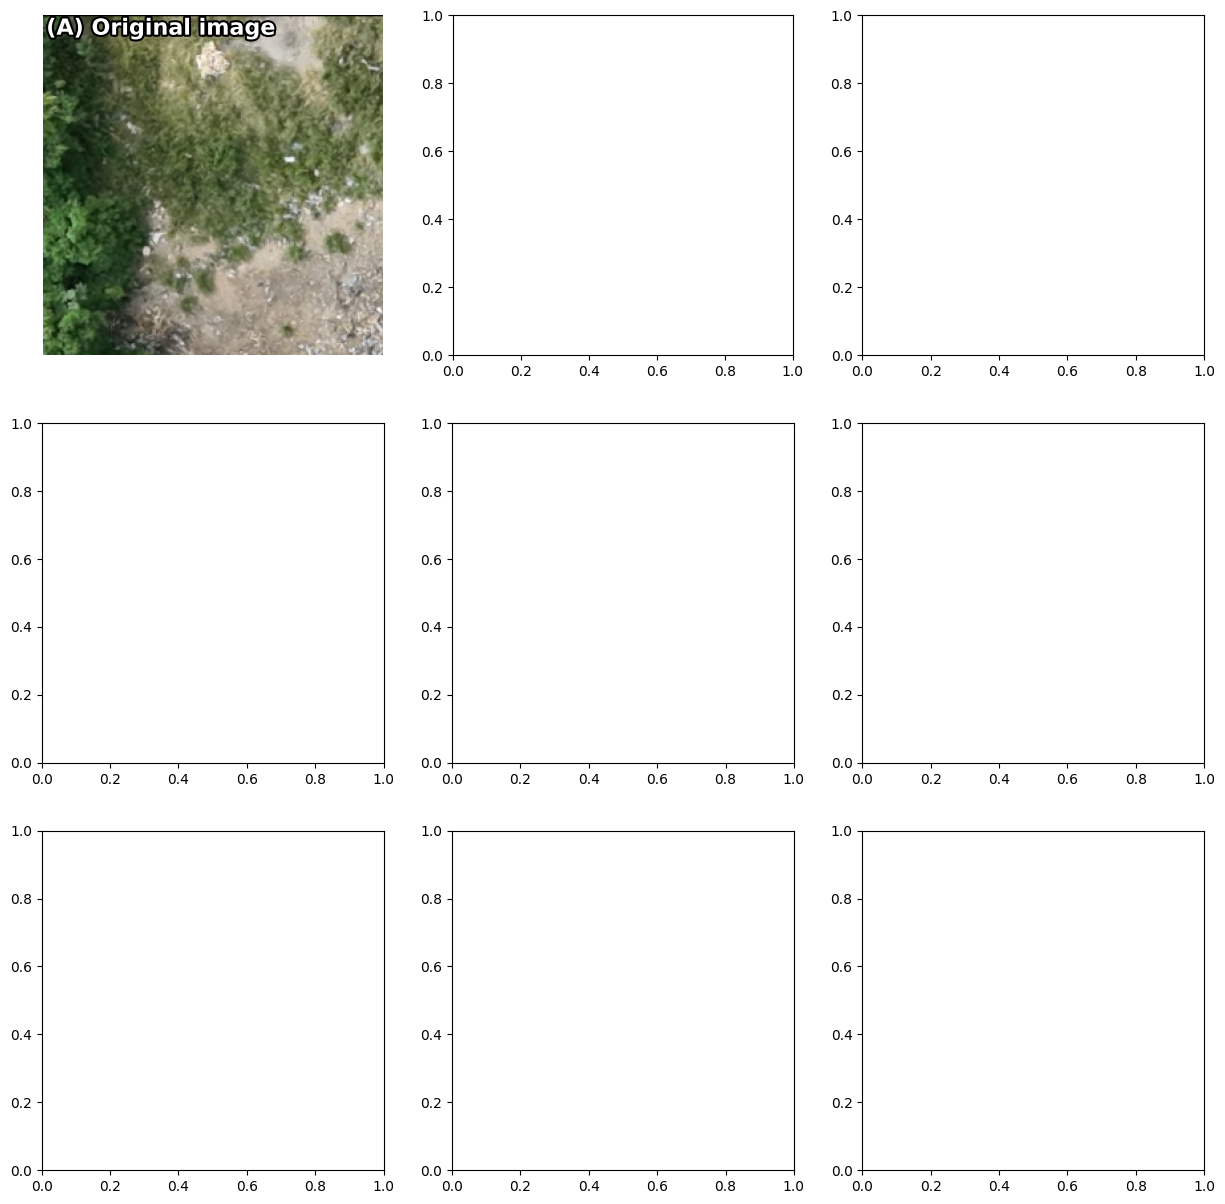

In [12]:
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects  # halo effect

# Select image 45
img_num = 45
pair_45 = [p for p in pairs if extract_number(p[0].name) == img_num]
if not pair_45:
    raise RuntimeError(f"Image {img_num} not found in matched pairs.")
img_path, mask_path = pair_45[0]

# Load original image
img_orig = tiff.imread(str(img_path)).astype(np.float32)
if img_orig.ndim == 2:
    img_orig = np.stack([img_orig]*3, -1)
elif img_orig.shape[-1] == 4:
    img_orig = img_orig[..., :3]

# Load mask
mask_orig = load_mask(mask_path)

# Sort scale factors in decreasing order (fine → coarse)
sorted_factors = sorted(res_factors, reverse=True)

# Letters for labeling
letters = "ABCDEFGHI"

# Function to add halo text
def add_halo_text(ax, text, x=0.01, y=0.99, fontsize=16):
    ax.text(
        x, y, text, fontsize=fontsize, fontweight="bold", color="white",
        va="top", ha="left", transform=ax.transAxes, zorder=2,
        path_effects=[path_effects.withStroke(linewidth=3, foreground='black')]
    )

# Initialize figure
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.flatten()

# First plot: original image
axes[0].imshow(tf.cast(img_orig, tf.uint8))
add_halo_text(axes[0], f"({letters[0]}) Original image")
axes[0].axis("off")

# Loop over remaining 8 scale factors
for i, f in enumerate(sorted_factors[:8], start=1):
    # Downsample with bilinear
    h, w = int(img_orig.shape[0]*f), int(img_orig.shape[1]*f)
    img_res = tf.image.resize(img_orig, (max(1,h), max(1,w)), method="bilinear")
    x = tf.image.resize(img_res, (256, 256), method="bilinear") / 255.0
    x = np.expand_dims(x, 0)

    # Predict mask
    pred = MODEL.predict(x, verbose=0)[0]
    pred_bin = (pred > 0.5).astype(np.uint8)

    # Compute ground resolution in cm/pixel
    res_cm = BASE_RES_M / f * 100
    axes[i].imshow(pred_bin, cmap="gray")
    add_halo_text(axes[i], f"({letters[i]}) {res_cm:.1f} cm/pixel")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

# ... (all your existing imports and setup remain the same)

results = []

for f in res_factors:
    print(f"\n--- scale factor {f} ---")
    y_true_all, y_pred_all = [], []

    for img_p, mask_p in pairs:
        img = tiff.imread(str(img_p)).astype(np.float32)
        if img.ndim == 2:
            img = np.stack([img]*3, -1)
        elif img.shape[-1] == 4:
            img = img[..., :3]

        mask = load_mask(mask_p)

        # downsample with bilinear, then back to 256x256
        h, w = int(img.shape[0]*f), int(img.shape[1]*f)
        img_res = tf.image.resize(img, (max(1,h), max(1,w)), method="bilinear")
        x = tf.image.resize(img_res, (256, 256), method="bilinear") / 255.0
        x = np.expand_dims(x, 0)

        pred = MODEL.predict(x, verbose=0)[0]
        pred_bin = (pred > 0.5).astype(np.uint8)

        y_true_all.append(mask.ravel())
        y_pred_all.append(pred_bin.ravel())

    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)

    # --- IoU calculation ---
    intersection = np.logical_and(y_true_all, y_pred_all).sum()
    union        = np.logical_or(y_true_all, y_pred_all).sum()
    iou = intersection / union if union > 0 else 0.0

    results.append({
        "scale_factor": f,
        "resolution_m_per_px": BASE_RES_M / f,
        "precision": precision_score(y_true_all, y_pred_all, zero_division=0),
        "recall":    recall_score(y_true_all, y_pred_all, zero_division=0),
        "f1":        f1_score(y_true_all, y_pred_all, zero_division=0),
        "iou":       iou,
    })

df = pd.DataFrame(results).sort_values("resolution_m_per_px")
print("\n=== Metrics vs ground resolution ===")
print(df)

# Plot IoU as well
plt.figure()
plt.plot(df["resolution_m_per_px"], df["precision"], "o-", label="Precision")
plt.plot(df["resolution_m_per_px"], df["recall"],    "o-", label="Recall")
plt.plot(df["resolution_m_per_px"], df["f1"],        "o-", label="F1")
plt.plot(df["resolution_m_per_px"], df["iou"],       "o-", label="IoU")
plt.xlabel("Ground resolution (m / pixel)  (fine → coarse)")
plt.ylabel("Score")
plt.title("U-Net performance vs ground resolution")
plt.grid(True)
plt.legend()
plt.show()


In [ ]:
import matplotlib.pyplot as plt

# Select the first image for demonstration
img_path, mask_path = pairs[0]

# Load original image
img_orig = tiff.imread(str(img_path)).astype(np.float32)
if img_orig.ndim == 2:
    img_orig = np.stack([img_orig]*3, -1)
elif img_orig.shape[-1] == 4:
    img_orig = img_orig[..., :3]

# Load mask
mask_orig = load_mask(mask_path)

# Sort scale factors in decreasing order (fine → coarse)
sorted_factors = sorted(res_factors, reverse=True)

# Initialize figure
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.flatten()

# First plot: original image
axes[0].imshow(tf.cast(img_orig, tf.uint8))
axes[0].set_title("Original image")
axes[0].axis("off")

# Loop over remaining 8 scale factors
for i, f in enumerate(sorted_factors[:8], start=1):
    # Downsample with bilinear
    h, w = int(img_orig.shape[0]*f), int(img_orig.shape[1]*f)
    img_res = tf.image.resize(img_orig, (max(1,h), max(1,w)), method="bilinear")
    x = tf.image.resize(img_res, (256, 256), method="bilinear") / 255.0
    x = np.expand_dims(x, 0)

    # Predict mask
    pred = MODEL.predict(x, verbose=0)[0]
    pred_bin = (pred > 0.5).astype(np.uint8)

    # Plot predicted mask
    axes[i].imshow(pred_bin, cmap="gray")
    axes[i].set_title(f"Pred. mask\nScale factor: {f}\nResolution: {BASE_RES_M/f:.3f} m/px")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


In [2]:
pwd

'c:\\Users\\Peter\\Documents\\GitHub\\mapping-waste-urban-africa\\scripts\\U-Net'